# VQE for a two-qubit H₂ Hamiltonian

This notebook is based on my original VQE exercises. I use the same two-layer circuit and compare statevector VQE with measurement-based VQE, including noise and readout mitigation.

In [1]:
import random
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize
import qiskit
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error, ReadoutError

## 1. VQE using Statevector

First I calculate the energy using the statevector, optimize the circuit parameters and compare the result with exact diagonalization.

[-0.00343156  1.89351194 -0.22020404  1.24788814]
-1.8572747922633346
-1.8572750301050402
The Error is: 2.3784170566365503e-07


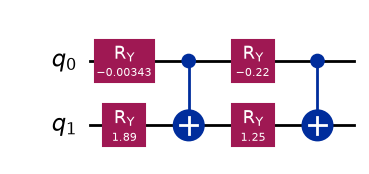

In [2]:
c_0 = -1.0523732458
c_1 = 0.3979374248
c_2 = -0.3979374248
c_3 = -0.0112801043
c_4 = 0.1809311998

#1:
z = np.array([[1, 0], [0, -1]])
x = np.array([[0, 1], [1, 0]])
I = np.array([[1, 0], [0, 1]])

#2:
H = c_0*np.kron(I, I) + c_1*np.kron(z, I) + c_2*np.kron(I, z) + c_3*np.kron(z, z) + c_4*np.kron(x, x)

#3, 4, 5:
def energy(theta):
    theta_1, theta_2, theta_3, theta_4 = theta[0], theta[1], theta[2], theta[3]
    qc = QuantumCircuit(2)
    qc.ry(theta_1, 0)
    qc.ry(theta_2, 1)
    qc.cx(0, 1)
    qc.ry(theta_3, 0)
    qc.ry(theta_4, 1)
    qc.cx(0, 1)
    statevector = Statevector.from_instruction(qc)
    psi = statevector.data
    energy = np.conj(psi) @ H @ psi
    return np.real(energy)

#6:
result = minimize(energy, x0 = [1.0, 1.0, 1.0, 1.0], method="COBYLA")

#7:
optimal_theta = result.x
minimum_energy = result.fun

print(optimal_theta)
print(minimum_energy)

#8:
eigenvalues, eigenvectors = np.linalg.eigh(H)
exact_energy = eigenvalues[0]
print(exact_energy)

#9:
print(f"The Error is: {abs(minimum_energy - exact_energy)}")

#10:
theta_1, theta_2, theta_3, theta_4 = result.x
qc = QuantumCircuit(2)
qc.ry(theta_1, 0)
qc.ry(theta_2, 1)
qc.cx(0, 1)
qc.ry(theta_3, 0)
qc.ry(theta_4, 1)
qc.cx(0, 1)

qc.draw('mpl')

## 2. VQE using measurement counts

Now I calculate the expectation values from Z and X basis measurements instead of using the statevector. I also compare ideal and noisy simulators.

Noisy VQE parameters: [-0.47965569  2.23573556  0.31783957  0.91077073]
Noisy VQE energy: -1.74537316105376
Ideal VQE parameters: [-0.36017442  2.0252332   0.09162491  0.92492056]
Ideal VQE energy: -1.8558522535705078
Exact ground-state energy: -1.8572750301050402
Noisy VQE error: 0.1119018690512803
Ideal VQE error: 0.0014227765345324883


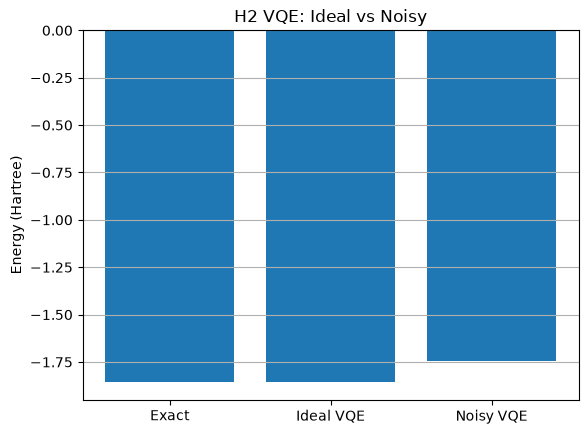

In [3]:
c_0 = -1.0523732458
c_1 = 0.3979374248
c_2 = -0.3979374248
c_3 = -0.0112801043
c_4 = 0.1809311998

I = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Z = np.array([[1, 0], [0, -1]])

#1:
H = (c_0 * np.kron(I, I)
     + c_1 * np.kron(Z, I)
     + c_2 * np.kron(I, Z)
     + c_3 * np.kron(Z, Z)
     + c_4 * np.kron(X, X))


#2:
noise_model = NoiseModel()

error_1q = depolarizing_error(0.01, 1)
error_2q = depolarizing_error(0.03, 2)

noise_model.add_all_qubit_quantum_error(error_1q, ["ry", "h"])
noise_model.add_all_qubit_quantum_error(error_2q, ["cx"])


readout_error = ReadoutError([
    [0.98, 0.02],
    [0.02, 0.98]
])

noise_model.add_all_qubit_readout_error(readout_error)


noisy_backend = AerSimulator(noise_model=noise_model)
ideal_backend = AerSimulator()

shots = 4096


#3: Define the variational circuit

def ansatz(theta):
    qc = QuantumCircuit(2)

    qc.ry(theta[0], 0)
    qc.ry(theta[1], 1)
    qc.cx(0, 1)

    qc.ry(theta[2], 0)
    qc.ry(theta[3], 1)
    qc.cx(0, 1)

    return qc


# 4. Calculate expectation values from counts

def z_expectations(counts):
    total = sum(counts.values())

    exp_ZI = 0
    exp_IZ = 0
    exp_ZZ = 0

    for bitstring, count in counts.items():

        # Qiskit bitstring order: q1 q0
        q1 = int(bitstring[0])
        q0 = int(bitstring[1])

        z1 = (-1)**q1
        z0 = (-1)**q0

        exp_ZI += z1 * count / total
        exp_IZ += z0 * count / total
        exp_ZZ += z1 * z0 * count / total

    return exp_ZI, exp_IZ, exp_ZZ


def xx_expectation(counts):
    total = sum(counts.values())
    exp_XX = 0

    for bitstring, count in counts.items():

        q1 = int(bitstring[0])
        q0 = int(bitstring[1])

        exp_XX += (-1)**(q1 + q0) * count / total

    return exp_XX

# 5. Define measurement-based energy function

def energy(theta, backend):

    # Z-basis measurement circuit
    qc_z = ansatz(theta)
    qc_z.measure_all()

    # X-basis measurement circuit
    qc_x = ansatz(theta)
    qc_x.h(0)
    qc_x.h(1)
    qc_x.measure_all()

    circuits = transpile([qc_z, qc_x], backend)

    result = backend.run(circuits, shots=shots).result()

    counts_z = result.get_counts(0)
    counts_x = result.get_counts(1)

    exp_ZI, exp_IZ, exp_ZZ = z_expectations(counts_z)
    exp_XX = xx_expectation(counts_x)

    energy_value = (
        c_0
        + c_1 * exp_ZI
        + c_2 * exp_IZ
        + c_3 * exp_ZZ
        + c_4 * exp_XX
    )

    return float(energy_value)

# 6. Run noisy VQE

theta_0 = [1.0, 1.0, 1.0, 1.0]

result_noisy = minimize(
    energy,
    x0=theta_0,
    args=(noisy_backend,),
    method="COBYLA",
    options={"maxiter": 300}
)

print("Noisy VQE parameters:", result_noisy.x)
print("Noisy VQE energy:", result_noisy.fun)


# 7. Run noiseless measurement-based VQE

result_ideal = minimize(
    energy,
    x0=theta_0,
    args=(ideal_backend,),
    method="COBYLA",
    options={"maxiter": 300}
)

print("Ideal VQE parameters:", result_ideal.x)
print("Ideal VQE energy:", result_ideal.fun)


# 8. Exact diagonalization

eigenvalues, eigenvectors = np.linalg.eigh(H)
exact_energy = eigenvalues[0]

print("Exact ground-state energy:", exact_energy)


# 9. Compare errors

print("Noisy VQE error:",
      abs(result_noisy.fun - exact_energy))

print("Ideal VQE error:",
      abs(result_ideal.fun - exact_energy))


# 10. Plot comparison

methods = ["Exact", "Ideal VQE", "Noisy VQE"]

energies = [
    exact_energy,
    result_ideal.fun,
    result_noisy.fun
]

plt.bar(methods, energies)

plt.ylabel("Energy (Hartree)")
plt.title("H2 VQE: Ideal vs Noisy")
plt.grid(axis="y")
plt.show()


## 3. Readout error mitigation

The readout errors change the measured bitstrings. Here I calibrate the measurement matrix by preparing the four computational basis states, then correct the measured probabilities.

I keep the optimized parameters from the statevector calculation fixed, so the comparison is about the energy measurement itself.

Readout calibration matrix:
[[9.6055e-01 2.1400e-02 1.9850e-02 1.5000e-04]
 [1.8550e-02 9.6080e-01 6.5000e-04 1.8400e-02]
 [2.0400e-02 4.5000e-04 9.6040e-01 2.0800e-02]
 [5.0000e-04 1.7350e-02 1.9100e-02 9.6065e-01]]
Exact ground-state energy: -1.8572750301050402
Statevector VQE energy: -1.8572747922633346
Noisy measurement energy: -1.7709660401733887
Readout-mitigated energy: -1.7858920378976817
Noisy error: 0.08630875208994593
Mitigated error: 0.07138275436565289


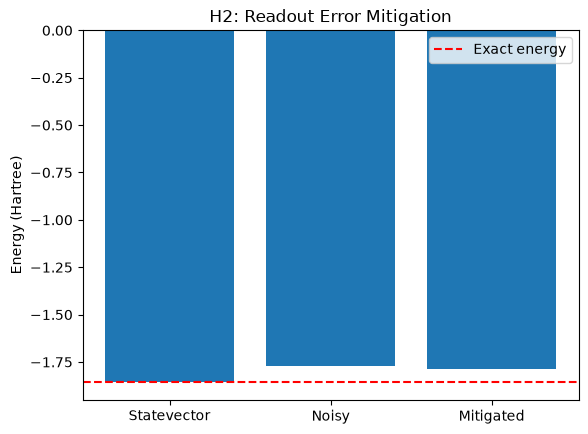

In [4]:
#1: Calibrate the readout matrix using the noisy backend
calibration_circuits = []
for state in ["00", "01", "10", "11"]:
    qc_cal = QuantumCircuit(2)
    if state[1] == "1":
        qc_cal.x(0)
    if state[0] == "1":
        qc_cal.x(1)
    qc_cal.measure_all()
    calibration_circuits.append(qc_cal)

# Only readout noise is used for calibration (not gate noise)
readout_noise = NoiseModel()
readout_noise.add_all_qubit_readout_error(readout_error)
calibration_backend = AerSimulator(noise_model=readout_noise)
calibration_result = calibration_backend.run(transpile(calibration_circuits, calibration_backend), shots=20000, seed_simulator=123).result()

bitstrings = ["00", "01", "10", "11"]
M = np.zeros((4, 4))
for j in range(4):
    counts = calibration_result.get_counts(j)
    for i, bitstring in enumerate(bitstrings):
        M[i, j] = counts.get(bitstring, 0) / 20000

print("Readout calibration matrix:")
print(M)

#2: Convert counts to probabilities and correct the readout errors
def corrected_probabilities(counts):
    total = sum(counts.values())
    p_measured = np.array([counts.get(s, 0) / total for s in bitstrings])
    p_corrected = np.linalg.solve(M, p_measured)
    # Small negative values can appear due to finite-shot fluctuations
    p_corrected = np.maximum(p_corrected, 0)
    p_corrected = p_corrected / np.sum(p_corrected)
    return p_corrected

#3: Calculate the energy from the corrected probabilities
def mitigated_energy(theta, backend, shots=4096, seed=123):
    qc_z = ansatz(theta)
    qc_z.measure_all()

    qc_x = ansatz(theta)
    qc_x.h(0)
    qc_x.h(1)
    qc_x.measure_all()

    circuits = transpile([qc_z, qc_x], backend)
    result = backend.run(circuits, shots=shots, seed_simulator=seed).result()
    p_z = corrected_probabilities(result.get_counts(0))
    p_x = corrected_probabilities(result.get_counts(1))

    # Bitstring order: 00, 01, 10, 11 (q1 q0)
    exp_ZI = p_z[0] + p_z[1] - p_z[2] - p_z[3]
    exp_IZ = p_z[0] - p_z[1] + p_z[2] - p_z[3]
    exp_ZZ = p_z[0] - p_z[1] - p_z[2] + p_z[3]
    exp_XX = p_x[0] - p_x[1] - p_x[2] + p_x[3]

    return c_0 + c_1*exp_ZI + c_2*exp_IZ + c_3*exp_ZZ + c_4*exp_XX

#4: Compare the energy with and without readout mitigation
# The parameters below come from the statevector VQE in section 1
theta_best = optimal_theta

energy_statevector = float(np.real(Statevector.from_instruction(ansatz(theta_best)).expectation_value(H)))
energy_noisy = energy(theta_best, noisy_backend)
energy_mitigated = mitigated_energy(theta_best, noisy_backend)

print("Exact ground-state energy:", exact_energy)
print("Statevector VQE energy:", energy_statevector)
print("Noisy measurement energy:", energy_noisy)
print("Readout-mitigated energy:", energy_mitigated)
print("Noisy error:", abs(energy_noisy - energy_statevector))
print("Mitigated error:", abs(energy_mitigated - energy_statevector))

plt.bar(["Statevector", "Noisy", "Mitigated"], [energy_statevector, energy_noisy, energy_mitigated])
plt.axhline(exact_energy, color="red", linestyle="--", label="Exact energy")
plt.ylabel("Energy (Hartree)")
plt.title("H2: Readout Error Mitigation")
plt.legend()
plt.show()

## 4. Check the statistical fluctuations

Because we use a finite number of shots, the energy changes between runs. Readout mitigation corrects measurement errors, but it cannot remove the gate noise.

Mean noisy energy: -1.7588649456625487
Mean mitigated energy: -1.789441331805102
Noisy standard deviation: 0.005734617096171276
Mitigated standard deviation: 0.006052558389255009


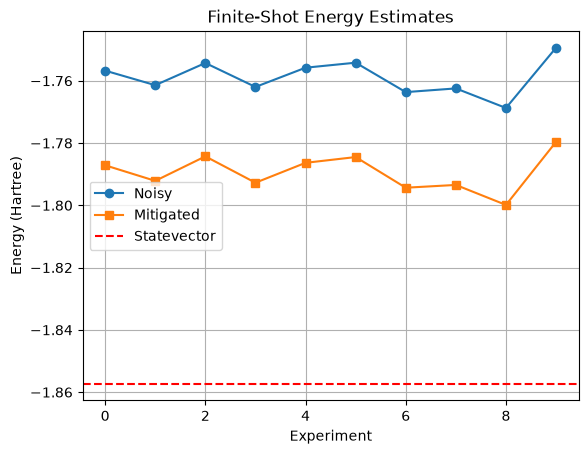

In [5]:
noisy_energies = []
mitigated_energies = []

for seed in range(10):
    # Use the same fixed circuit parameters in each experiment
    qc_z = ansatz(theta_best)
    qc_z.measure_all()
    qc_x = ansatz(theta_best)
    qc_x.h(0)
    qc_x.h(1)
    qc_x.measure_all()

    circuits = transpile([qc_z, qc_x], noisy_backend)
    results = noisy_backend.run(circuits, shots=4096, seed_simulator=seed).result()
    counts_z = results.get_counts(0)
    counts_x = results.get_counts(1)

    exp_ZI, exp_IZ, exp_ZZ = z_expectations(counts_z)
    exp_XX = xx_expectation(counts_x)
    e_noisy = c_0 + c_1*exp_ZI + c_2*exp_IZ + c_3*exp_ZZ + c_4*exp_XX
    noisy_energies.append(e_noisy)

    p_z = corrected_probabilities(counts_z)
    p_x = corrected_probabilities(counts_x)
    e_mitigated = (c_0 + c_1*(p_z[0]+p_z[1]-p_z[2]-p_z[3])
                   + c_2*(p_z[0]-p_z[1]+p_z[2]-p_z[3])
                   + c_3*(p_z[0]-p_z[1]-p_z[2]+p_z[3])
                   + c_4*(p_x[0]-p_x[1]-p_x[2]+p_x[3]))
    mitigated_energies.append(e_mitigated)

print("Mean noisy energy:", np.mean(noisy_energies))
print("Mean mitigated energy:", np.mean(mitigated_energies))
print("Noisy standard deviation:", np.std(noisy_energies, ddof=1))
print("Mitigated standard deviation:", np.std(mitigated_energies, ddof=1))

plt.plot(noisy_energies, "o-", label="Noisy")
plt.plot(mitigated_energies, "s-", label="Mitigated")
plt.axhline(energy_statevector, color="red", linestyle="--", label="Statevector")
plt.xlabel("Experiment")
plt.ylabel("Energy (Hartree)")
plt.title("Finite-Shot Energy Estimates")
plt.legend()
plt.grid(True)
plt.show()